# 0.2 Benchmarks

Where do commercial claims (Ecovative and its GIY kit, plus the companies in `MycoMaterials/mycomaterials_benchmarks.xlsx`) sit against the lab datasets in `data/interim/extracted/`?

**Status of each benchmark value** (column `status` below)
- `checked`: read directly on grow.bio, in the patent text or in the Elsacker 2023 review.
- `patent`: Gemini found it in an uploaded patent and gave an exact quote (`MycoMaterials/Germini/germini_r1.xlsx` and `patent_benchmark_verification_notes.md`, 2026-10-11).
- `no_source`: no patent or primary source found. Kept in the table, left off the charts.

**Reference** (columns `ref` and `where`): the key of the full reference in the References section at the end (P = patent, R = review, W = maker web page), and where in it the value sits.

**Kind of value** (column `kind`): `measured` is a test result or worked example; `claim` is a claimed or preferred range written into the patent. Measured values are drawn solid, claims dashed.

Commercial figures are reference marks, never model training rows.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

from mycodemo.config import INTERIM_DATA_DIR

EXTRACTED_DIR = INTERIM_DATA_DIR / "extracted"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# One colour per source family; each of our studies gets its own colour and marker shape
OURS, ECO, OTHER = "#2a78d6", "#eb6834", "#008300"
FAMILY_COLOUR = {"eco": ECO, "other": OTHER}
DATASET_STYLE = {  # colour, marker
    "d004": ("#2a78d6", "o"),
    "d005": ("#1baf7a", "s"),
    "d007": ("#6250d6", "^"),
    "d016": ("#e87ba4", "v"),
}
NAMES = {
    "d002": "Musci 2025", "d003": "Gomaa 2024", "d004": "Bhaskar 2026", "d005": "Elsacker 2019",
    "d006": "Hysek 2025", "d007": "Irbe 2026", "d009": "Elsacker 2022", "d016": "Vašatko 2022",
    "d012": "Pacheco-Sanchez 2026", "d017": "Jiménez-Obando 2025",
    "d023": "Houette 2022",
}

2026-10-11 22:55:49.709 | INFO     | mycodemo.config:<module>:11 - PROJ_ROOT path is: /home/sylas/Desktop/mycodemo


## 1. Benchmark values

Typed in here rather than kept as a new CSV. **One row per benchmark**, with one column pair per property and the unit in the column name: `density_kg_m3`, `stress_MPa` (compressive), `tensile_MPa`, `days`, `temp_C`, plus `thermal_W_mK`. An empty cell means the source gives no value. `_lo` = `_hi` means a single value; an empty `_hi` with a filled `_lo` means the source gives only a lower limit (">").

When a product has both a claimed range and a measured example from the same source, they are two rows (for example "SQIM ephea, claim" and "SQIM ephea, example"), so `kind` and `status` always describe the whole row. GIY conversions: 7.6 lb/ft³ ≈ 122 kg/m³, 18 psi ≈ 0.124 MPa.

In [2]:
# One row per benchmark (a product, or one claim/example within a product).
# Each property has its own column pair with the unit in the name; empty = the source gives no value.
# _lo = _hi means a single value; an empty _hi with a filled _lo means "more than" (lower limit only).
PROPS = ["density_kg_m3", "stress_MPa", "tensile_MPa", "days", "temp_C"]
cols = (["benchmark", "maker", "family", "kind", "status", "ref", "where"]
        + [f"{p}_{e}" for p in PROPS for e in ("lo", "hi")]
        + ["thermal_W_mK", "note"])

rows = [
    # Ecovative and its GIY kit
    dict(benchmark="GIY kit material", maker="Ecovative", family="eco", kind="measured", status="checked",
         ref="W1, W3", where="product page; FAQ",
         density_kg_m3_lo=122, density_kg_m3_hi=122, stress_MPa_lo=0.124, stress_MPa_hi=0.124,
         note="maker's spec, no replicates; stress at 15% strain; flexural 0.23 MPa; dries to 35% of original weight, shrinks 4% (X, Y) and 7% (Z)"),
    dict(benchmark="GIY kit", maker="Ecovative", family="eco", kind="measured", status="checked",
         ref="W2, W3", where="instructions; FAQ",
         days_lo=7, days_hi=10, temp_C_lo=22, temp_C_hi=22,
         note="thin parts, pre-colonised material; about 7 d from hydrated, 10 d from dehydrated material"),
    dict(benchmark="Grown.bio kit (EU licensee)", maker="Ecovative", family="eco", kind="measured", status="checked",
         ref="W4", where="steps 3 and 4",
         days_lo=6, days_hi=7, temp_C_lo=22, temp_C_hi=26, note="4–5 d in mould + 2 d out"),
    dict(benchmark="Ecovative grown materials", maker="Ecovative", family="eco", kind="measured", status="checked",
         ref="P2", where="Examples 4 and 6",
         days_lo=14, days_hi=14, temp_C_lo=24, temp_C_hi=24, note="P. ostreatus, 75 °F, 100% RH"),
    dict(benchmark="Ecovative moulded packaging, claim", maker="Ecovative", family="eco", kind="claim", status="patent",
         ref="P3", where="operating parameters table",
         days_lo=3, days_hi=12, note="worked example 5 + 4 = 9 days"),
    dict(benchmark="Ecovative moulded packaging, example", maker="Ecovative", family="eco", kind="measured", status="patent",
         ref="P3", where="operating parameters table",
         temp_C_lo=18, temp_C_hi=24, note="65 °F cooled air, 75 °F air; vessel below 35 °C"),
    dict(benchmark="Ecovative moulded packaging, review figures", maker="Ecovative", family="eco", kind="claim", status="no_source",
         ref="", where="review literature per Gemini (Jones 2017, Girometta 2019)",
         density_kg_m3_lo=50, density_kg_m3_hi=250, stress_MPa_lo=0.2, stress_MPa_hi=1.5, thermal_W_mK=0.040,
         note="not in P3"),
    dict(benchmark="Ecovative AirMycelium", maker="Ecovative", family="eco", kind="claim", status="checked",
         ref="R1", where="section on aerial mycelium",
         temp_C_lo=30, temp_C_hi=32, note="process described from Ecovative patents"),
    dict(benchmark="Ecovative AirMycelium, unverified", maker="Ecovative", family="eco", kind="claim", status="no_source",
         ref="", where="Gemini; not found in R1",
         density_kg_m3_lo=10, density_kg_m3_hi=800, days_lo=9, days_hi=14,
         note="10–150 kg/m³ loose, 400–800 pressed"),
    dict(benchmark="Ecovative fruiting-body shapes", maker="Ecovative", family="eco", kind="measured", status="patent",
         ref="P1", where="Examples 1 and 2",
         days_lo=28, days_hi=75, temp_C_lo=21, temp_C_hi=24, note="21–45 d incubation + 7–30 d fruiting"),
    dict(benchmark="Raw fruiting-body tissue", maker="Ecovative", family="eco", kind="measured", status="patent",
         ref="P1", where="col. 1",
         density_kg_m3_lo=180, density_kg_m3_hi=390,
         note="cap 180, stipe up to 350, spore tubes 340–390; tissue, not composite"),
    # Other companies
    dict(benchmark="Okom Wrks boards", maker="Okom Wrks", family="other", kind="claim", status="patent",
         ref="P7", where="claims 1, 2, 12–14 and 19",
         density_kg_m3_lo=250, stress_MPa_lo=1.2, days_lo=4, days_hi=17, temp_C_lo=22, temp_C_hi=26,
         note="> 0.25 g/cm³ and > 1.2 MPa ultimate compressive strength (lower limits only)"),
    dict(benchmark="Okom Wrks example", maker="Okom Wrks", family="other", kind="measured", status="patent",
         ref="P7", where="Example 1",
         density_kg_m3_lo=250, density_kg_m3_hi=250, stress_MPa_lo=0.98, stress_MPa_hi=0.98,
         note="hollow cylinder, n = 1; strain not given; below its own 1.2 MPa claim"),
    dict(benchmark="Processed mycelium leather", maker="Bolt Threads; BLC Leather Technology Centre", family="other",
         kind="measured", status="patent", ref="P4", where="Table 1",
         density_kg_m3_lo=620, density_kg_m3_hi=621, tensile_MPa_lo=2.87, tensile_MPa_hi=3.69,
         note="G. sessile mats; tensile = means of treatments A and B (SD 1.3–1.4), n = 42 and 47"),
    dict(benchmark="SQIM ephea, uncoated", maker="Mogu / SQIM", family="other", kind="claim", status="patent",
         ref="P5", where="p. 6", tensile_MPa_lo=0.5, tensile_MPa_hi=5, note="ISO 3376"),
    dict(benchmark="SQIM ephea, coated", maker="Mogu / SQIM", family="other", kind="claim", status="patent",
         ref="P5", where="p. 8", tensile_MPa_lo=8, tensile_MPa_hi=50, note="coating about 8× stronger in Example 4"),
    dict(benchmark="SQIM ephea, claim", maker="Mogu / SQIM", family="other", kind="claim", status="patent",
         ref="P5", where="p. 5", days_lo=10, days_hi=18, note="preferred mat incubation; Example 2 used 14 d"),
    dict(benchmark="SQIM ephea, example", maker="Mogu / SQIM", family="other", kind="measured", status="patent",
         ref="P5", where="Example 2", temp_C_lo=23, temp_C_hi=28),
    dict(benchmark="Bolt Threads Mylo", maker="Bolt Threads", family="other", kind="claim", status="patent",
         ref="P6", where="paras. 0120 and 0148",
         tensile_MPa_lo=5, tensile_MPa_hi=30, temp_C_lo=20, temp_C_hi=35,
         note="wet tensile strength; growth days not stated"),
    dict(benchmark="Ford plasticised composites", maker="Ford", family="other", kind="claim", status="patent",
         ref="P8", where="cols. 4 and 7",
         days_lo=1, days_hi=15, temp_C_lo=13, temp_C_hi=32, note="55–90 °F"),
    dict(benchmark="MycoWorks Fine Mycelium", maker="MycoWorks", family="other", kind="claim", status="no_source",
         ref="", where="Gemini; tensile not found, days not in R1",
         tensile_MPa_lo=10, tensile_MPa_hi=25, days_lo=14, days_hi=18),
    dict(benchmark="Mushroom Material pellets", maker="Mushroom Material", family="other", kind="claim", status="no_source",
         ref="", where="news release per Gemini",
         density_kg_m3_lo=40, density_kg_m3_hi=120, days_lo=6, days_hi=8),
    dict(benchmark="Biohm MycoPanel", maker="Biohm", family="other", kind="claim", status="no_source",
         ref="", where="marketing per Gemini", thermal_W_mK=0.024, note="below still air (~0.026): likely wrong"),
    dict(benchmark="Mykor MykoFoam", maker="Mykor", family="other", kind="claim", status="no_source",
         ref="", where="Innovate UK case study per Gemini", thermal_W_mK=0.030),
    dict(benchmark="Loop Living Cocoon", maker="Loop Biotech", family="other", kind="claim", status="no_source",
         ref="", where="product page per Gemini", days_lo=7, days_hi=7),
]
bench = pd.DataFrame(rows, columns=cols)
shown = bench[bench.status != "no_source"]  # charts use only checked and patent values

print(bench.status.value_counts().to_string())
bench


status
patent       21
no_source    13
checked       8


,benchmark,maker,family,property,lo,hi,kind,status,source,note
0,GIY kit material,Ecovative,eco,density,122.000,122.000,measured,checked,grow.bio product page,"maker's spec sheet value, no replicates"
1,GIY kit material,Ecovative,eco,stress,0.124,0.124,measured,checked,grow.bio product page,at 15% strain; flexural 0.23 MPa
2,GIY kit,Ecovative,eco,days,7.000,10.000,measured,checked,grow.bio FAQ and instructions,"thin parts, pre-colonised material"
3,GIY kit,Ecovative,eco,temp,22.000,22.000,measured,checked,grow.bio instructions,
4,Grown.bio kit (EU licensee),Ecovative,eco,days,6.000,7.000,measured,checked,Grown.bio kit manual,
5,Grown.bio kit (EU licensee),Ecovative,eco,temp,22.000,26.000,measured,checked,Grown.bio kit manual,
6,Ecovative grown materials,Ecovative,eco,days,14.000,14.000,measured,checked,"US9485917B2, Examples 4 and 6",P. ostreatus
7,Ecovative grown materials,Ecovative,eco,temp,24.000,24.000,measured,checked,"US9485917B2, Examples 4 and 6","75 °F, 100% RH"
8,Ecovative moulded packaging,Ecovative,eco,days,3.000,12.000,claim,patent,"US11343979B2, operating parameters table",worked example 5 + 4 = 9 days
9,Ecovative moulded packaging,Ecovative,eco,temp,18.000,24.000,measured,patent,"US11343979B2, operating parameters table","65 °F cooled air, 75 °F air; vessel below 35 °C"


## 2. Our data: density and stress per row, growth days and temperature per dataset

In [3]:
meas = pd.read_csv(EXTRACTED_DIR / "measurement.csv")
sample = pd.read_csv(EXTRACTED_DIR / "sample.csv")
ferm = pd.read_csv(EXTRACTED_DIR / "fermentation.csv")

props = meas.rename(columns={"compressive_stress_at_10pct_strain_MPa": "stress",
                             "dry_density_kg_m3": "density"})
both = props.dropna(subset=["stress", "density"])
dens = props.dropna(subset=["density"])

growth = (sample.merge(ferm, on="fermentation_id")
          .groupby("dataset_id")[["total_growth_days", "incubation_temp_c"]]
          .agg(["min", "max"]))
growth.columns = ["days_lo", "days_hi", "temp_lo", "temp_hi"]

print(f"{len(both)} rows have both density and stress, from {both.dataset_id.nunique()} datasets")
print(f"{len(dens)} rows have density, from {dens.dataset_id.nunique()} datasets")
growth

108 rows have both density and stress, from 4 datasets
187 rows have density, from 7 datasets


,days_lo,days_hi,temp_lo,temp_hi
dataset_id,,,,
d002,28.0,28.0,24.0,24.0
d003,13.0,13.0,28.0,28.0
d004,14.0,14.0,NaN,NaN
d005,16.0,19.0,24.0,28.0
d006,29.0,29.0,24.0,24.0
d007,21.0,21.0,22.0,22.0
d009,22.0,22.0,26.0,26.0
d012,NaN,NaN,19.0,19.0
d016,14.0,17.0,NaN,NaN


## 3. Density against compressive strength, coloured by study

Both axes are logarithmic. Our values are stress at 10% strain. GIY is at 15% strain, which reads a little higher. The Okom example is an ultimate compressive strength with no strain given. Hollow markers are group means, filled markers single blocks.

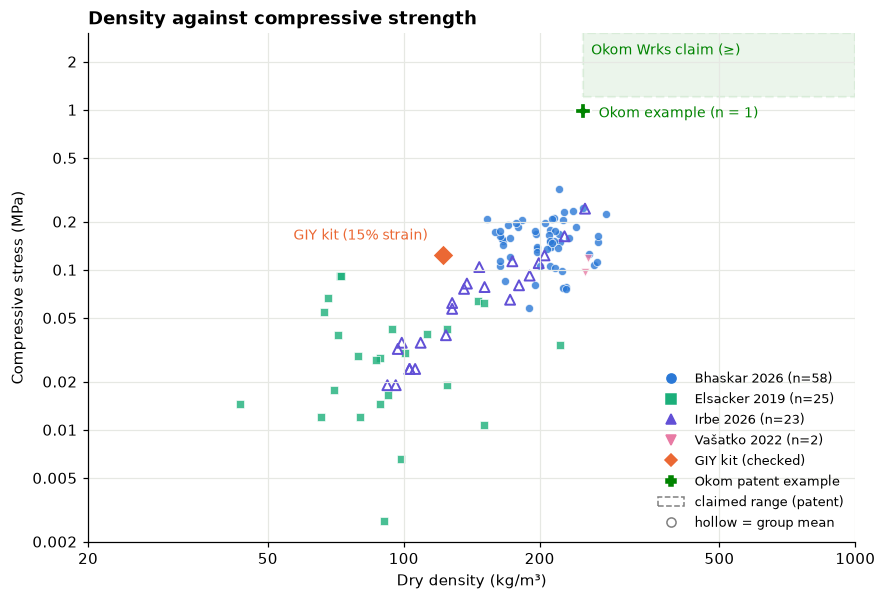

In [4]:
def pick(name, prop):
    """Lower value of one property for one benchmark row."""
    return shown.loc[shown.benchmark == name, f"{prop}_lo"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 6))
ax.set(xscale="log", yscale="log", xlim=(20, 1000), ylim=(0.002, 3),
       xlabel="Dry density (kg/m³)", ylabel="Compressive stress (MPa)")
ax.grid(True, which="major", color="#e6e8e3", lw=0.8)
xt, yt = [20, 50, 100, 200, 500, 1000], [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2]
ax.set_xticks(xt, [str(v) for v in xt])
ax.set_yticks(yt, [str(v) for v in yt])
ax.minorticks_off()

# Okom claimed region (lower limits only, so the box runs to the chart edge)
d, s = pick("Okom Wrks boards", "density_kg_m3"), pick("Okom Wrks boards", "stress_MPa")
ax.add_patch(Rectangle((d, s), 1000 - d, 3 - s, facecolor=OTHER, alpha=0.08,
                       edgecolor=OTHER, ls="--", lw=1.5))
ax.text(d * 1.04, 2.6, "Okom Wrks claim (≥)", color=OTHER, fontsize=9, va="top")

# Our studies
for ds, (colour, marker) in DATASET_STYLE.items():
    d = both[both.dataset_id == ds]
    raw, mean = d[d.measurement_type == "raw"], d[d.measurement_type == "mean"]
    ax.scatter(raw.density, raw.stress, c=colour, marker=marker, s=28, alpha=0.8,
               edgecolors="white", linewidths=0.5)
    ax.scatter(mean.density, mean.stress, facecolors="none", edgecolors=colour,
               marker=marker, s=42, linewidths=1.3)

# Single measured benchmark points
points = [("GIY kit material", ECO, "D", "GIY kit (15% strain)", (-10, 10), "right"),
          ("Okom Wrks example", OTHER, "P", "Okom example (n = 1)", (10, -4), "left")]
for name, colour, marker, label, offset, ha in points:
    x, y = pick(name, "density_kg_m3"), pick(name, "stress_MPa")
    ax.scatter([x], [y], marker=marker, s=110, c=colour, edgecolors="white", linewidths=1.5, zorder=5)
    ax.annotate(label, (x, y), xytext=offset, textcoords="offset points", ha=ha,
                color=colour, fontsize=9)

handles = [Line2D([], [], ls="", marker=m, color=c, label=f"{NAMES[ds]} (n={len(both[both.dataset_id == ds])})")
           for ds, (c, m) in DATASET_STYLE.items()]
handles += [Line2D([], [], ls="", marker="D", color=ECO, label="GIY kit (checked)"),
            Line2D([], [], ls="", marker="P", color=OTHER, label="Okom patent example"),
            Patch(facecolor="none", edgecolor="grey", ls="--", label="claimed range (patent)"),
            Line2D([], [], ls="", marker="o", mfc="none", color="grey", label="hollow = group mean")]
ax.legend(handles=handles, loc="lower right", fontsize=8.5, frameon=False)
ax.set_title("Density against compressive strength", loc="left", fontweight="bold")
plt.show()

**What it shows:** the two sourced commercial points sit at the top of our cloud, not above it. The GIY kit (122 kg/m³, 0.12 MPa) lands among the lab blocks. The Okom example (250 kg/m³, 0.98 MPa) is stronger than any lab block at that density, but it falls short of its own patent claim of 1.2 MPa. Ecovative's moulded-packaging box from the first version is gone because no patent gives those numbers. Within each colour, density predicts strength only weakly.

In [6]:
def range_rows(ax, items, xmax, invert=True):
    """One horizontal bar (or dot) per item; items are (label, lo, hi, colour, dashed)."""
    for i, (label, lo, hi, colour, dashed) in enumerate(items):
        if pd.isna(lo):
            continue
        open_hi = pd.isna(hi)
        hi = xmax if open_hi else hi
        if lo == hi:
            ax.scatter([lo], [i], c=colour, s=45, zorder=3, edgecolors="white")
        else:
            ax.barh(i, hi - lo, left=lo, height=0.5,
                    color=colour, alpha=0.15 if dashed else 0.85,
                    edgecolor=colour, ls="--" if dashed else "-", lw=1.3)
        if open_hi:
            ax.annotate("", (xmax, i), (xmax * 0.9 if ax.get_xscale() == "log" else xmax - 1, i),
                        arrowprops=dict(arrowstyle="->", color=colour))
    ax.set_yticks(range(len(items)), [it[0] for it in items])
    if invert:  # only once per shared y-axis
        ax.invert_yaxis()
    ax.grid(True, axis="x", color="#e6e8e3", lw=0.8)


def bench_items(prop):
    """Benchmark rows for one property, as range_rows items (claims dashed)."""
    b = shown.dropna(subset=[f"{prop}_lo"])
    return [(r.benchmark, r[f"{prop}_lo"], r[f"{prop}_hi"], FAMILY_COLOUR[r.family], r.kind == "claim")
            for _, r in b.iterrows()]

## 4. Density of every source

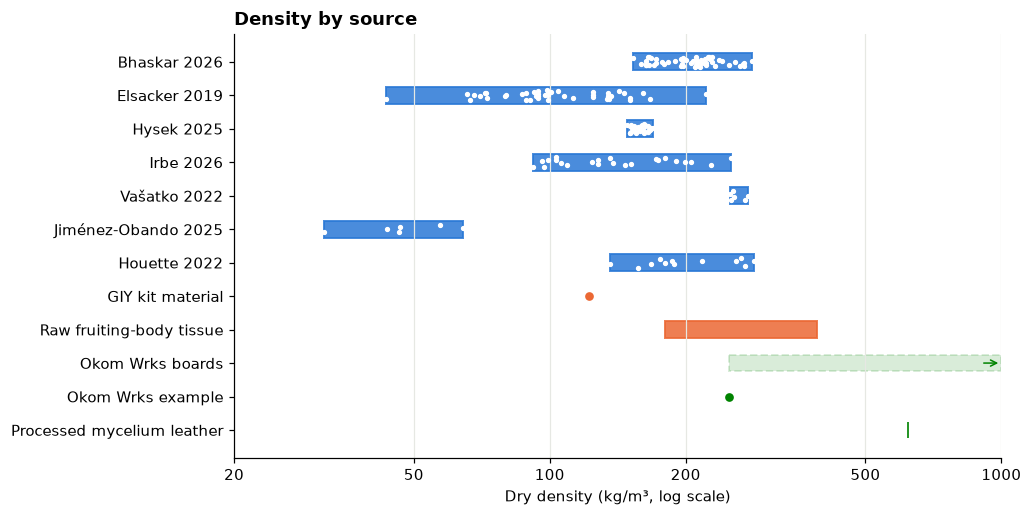

In [7]:
items, dots = [], []
for ds in ["d004", "d005", "d006", "d007", "d016", "d017", "d023"]:
    v = dens.loc[dens.dataset_id == ds, "density"]
    items.append((NAMES[ds], v.min(), v.max(), OURS, False))
    dots.append(v.values)
items += bench_items("density_kg_m3")

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xscale("log")
ax.set_xlim(20, 1000)
ax.set_xticks([20, 50, 100, 200, 500, 1000], ["20", "50", "100", "200", "500", "1000"])
ax.minorticks_off()
range_rows(ax, items, 1000)
for i, v in enumerate(dots):  # individual rows on top of our bars
    ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)),
               s=6, c="white", zorder=4)
ax.set_xlabel("Dry density (kg/m³, log scale)")
ax.set_title("Density by source", loc="left", fontweight="bold")
plt.show()

**What it shows:** lab blocks run from about 30 to 280 kg/m³. GIY sits in the middle of that band and Okom at its top. Pressed leather mats (about 620 kg/m³) and raw fruiting-body tissue (180–390 kg/m³) are different materials, shown for scale.

## 5. Growth time and temperature

A missing bar means the source gives no value. The syldd batch is left out until it finishes.

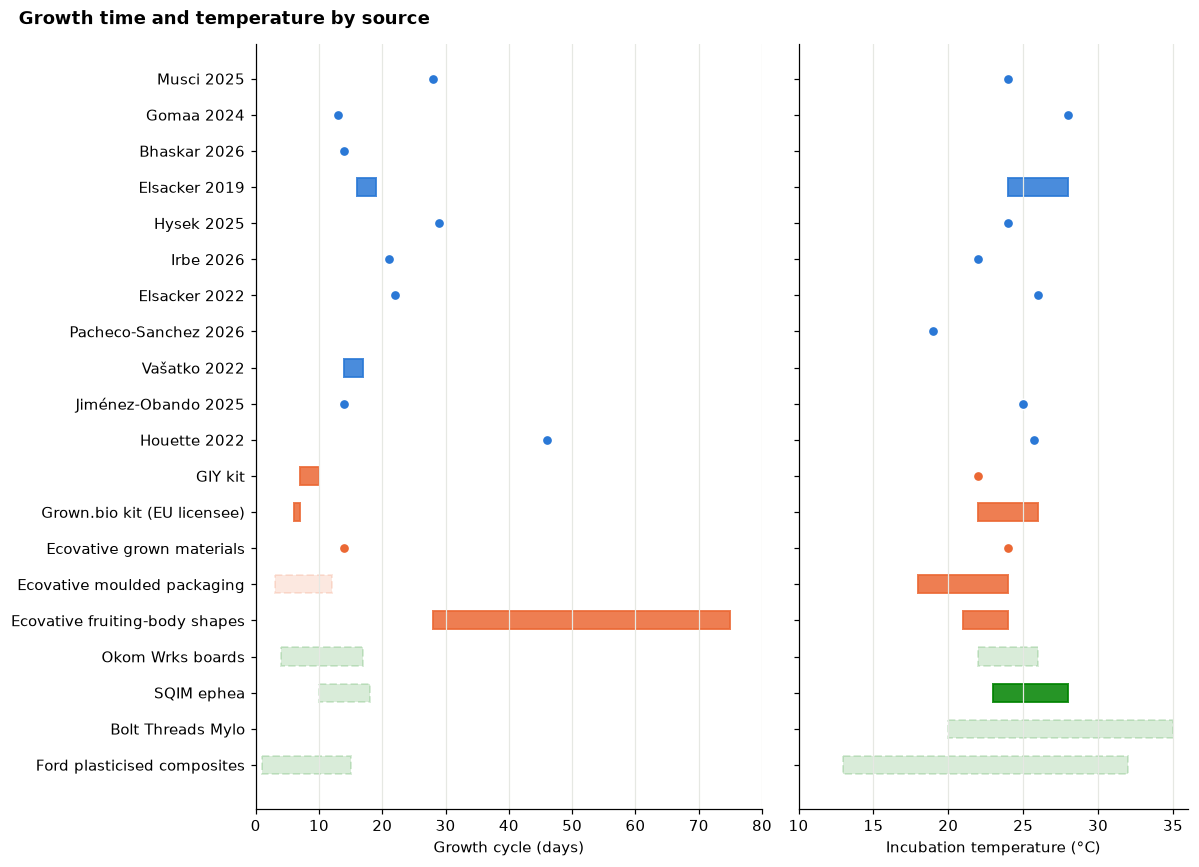

In [8]:
items_d, items_t = [], []
for ds, g in growth.iterrows():
    items_d.append((NAMES.get(ds, ds), g.days_lo, g.days_hi, OURS, False))
    items_t.append((NAMES.get(ds, ds), g.temp_lo, g.temp_hi, OURS, False))
for _, r in shown.dropna(subset=["days_lo", "temp_C_lo"], how="all").iterrows():
    colour, dashed = FAMILY_COLOUR[r.family], r.kind == "claim"
    items_d.append((r.benchmark, r.days_lo, r.days_hi, colour, dashed))  # empty cells draw no bar
    items_t.append((r.benchmark, r.temp_C_lo, r.temp_C_hi, colour, dashed))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 9), sharey=True,
                             gridspec_kw={"width_ratios": [1.3, 1]})
a1.set_xlim(0, 80)
a2.set_xlim(10, 36)
range_rows(a1, items_d, 80)
range_rows(a2, items_t, 36, invert=False)
a1.set_xlabel("Growth cycle (days)")
a2.set_xlabel("Incubation temperature (°C)")
fig.suptitle("Growth time and temperature by source", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**What it shows:** the kits and the packaging patent finish in 3–14 days at 18–26 °C. Most lab studies took 14–29 days, and Houette 2022 took 46. Kits use thin parts and pre-colonised material, so their days are not a fair target for M1a in a 3D mould. Ecovative's fruiting-body shapes (28–75 days) are the one commercial route slower than the lab.

## 6. Tensile strength of mycelium leathers

None of our studies measures tensile strength, so these stand alone for now.

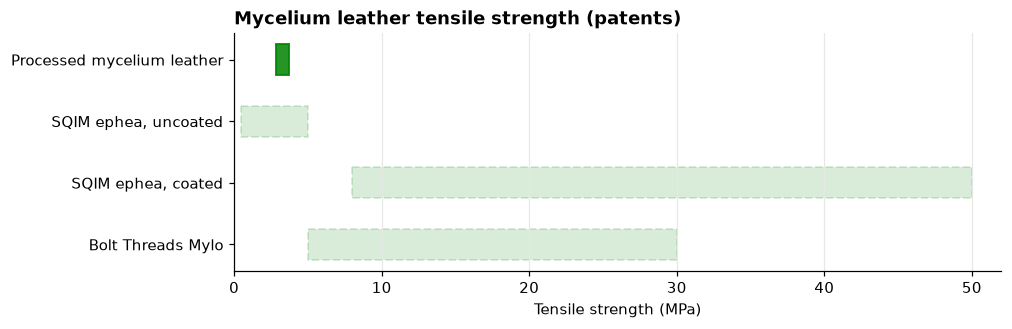

In [9]:
items = bench_items("tensile_MPa")
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.set_xlim(0, 52)
range_rows(ax, items, 52)
ax.set_xlabel("Tensile strength (MPa)")
ax.set_title("Mycelium leather tensile strength (patents)", loc="left", fontweight="bold")
plt.show()

**What it shows:** the only measured leather values (2.9 and 3.7 MPa, US20220007777A1, Bolt Threads and BLC) sit at the low end of every claimed range. The claims run up to 50 MPa for coated SQIM material. Claims in patents are what the applicant wants to protect, not what they achieved.

## 7. Caveats

- Commercial values are reference marks without replicates (except the leather table), never training rows.
- Strain differs: ours 10%, GIY 15%, Okom not stated.
- Kit and factory cycle days use thin parts and pre-colonised material, so they are not a fair target for M1a in a 3D mould.
- `no_source` rows (Ecovative packaging density and strength, AirMycelium, MycoWorks, Mushroom Material, Biohm, Mykor, Loop) stay in the table only. Biohm's 0.024 W/m·K is below still air and is probably wrong.
- US20220007777A1 belongs to Bolt Threads and BLC Leather Technology Centre (front page and Google Patents, checked 2026-10-11). Gemini's first sheet wrongly credited it to MycoWorks.
- Four values Gemini credited to the Elsacker 2023 review were checked against it: only the AirMycelium temperature (30–32 °C) is there. AirMycelium density and days, and MycoWorks days, stay `no_source`.

## References

Front-page details checked on Google Patents, Frontiers and grow.bio on 2026-10-11; first compiled by Gemini (`MycoMaterials/Germini/gemini_patent_citations.csv`, `gemini_review_citation.csv`).

**Patents**
- **P1** Bayer, E., & McIntyre, G. (2011). *Method for producing rapidly renewable chitinous material using fungal fruiting bodies and product made thereby* (US8001719B2). Ecovative Design LLC. Filed 2009-06-16, granted 2011-08-23.
- **P2** Bayer, E., & McIntyre, G. (2016). *Method for producing grown materials and products made thereby* (US9485917B2). Ecovative Design LLC. Filed 2007-12-12, granted 2016-11-08.
- **P3** Mueller, P. J., Winiski, J. M., & O'Brien, M. A. (2022). *Process and apparatus for producing mycelium biomaterial* (US11343979B2). Ecovative Design LLC. Filed 2019-05-22, granted 2022-05-31.
- **P4** Wang, J., Bansal Mutalik, R., Smith, M. J., Subler, N. E., Mckenzie, L., Collins, I. S., Flowers, K., Addy, V., Bainbridge, J. M., & Heinrich, M. J. (2022). *Methods of generating mycelium materials with improved properties* (US20220007777A1). Bolt Threads Inc.; BLC Leather Technology Centre Ltd. Filed 2019-11-14, published 2022-01-13.
- **P5** Gandia, A., Cielo, D., Montalti, M., Babbini, S., & Belotti, G. (2021). *Fungal mat coating method and bio-based composite materials obtained therefrom* (WO2021245608A1). Mogu Srl. Filed 2021-06-04, published 2021-12-09.
- **P6** Bakhtiary Davijani, A. A. (2022). *A composite material with enhanced resistance, and methods for production thereof* (WO2022226322A1). Bolt Threads Inc. Filed 2022-04-22, published 2022-10-27.
- **P7** English, J. (2024). *Method for creating a stiff, rigid mycelium-based biocomposite material for use in structural and non-structural applications* (US11866691B2). Okom Wrks Labs PBC. Filed 2021-06-10, granted 2024-01-09.
- **P8** Rocco, C. A., & Kalisz, R. E. (2012). *Plasticized mycelium composite and method* (US8227225B2). Ford Global Technologies LLC. Filed 2010-06-09, granted 2012-07-24.
- **P9** Ross, P. (2016). *Method for producing fungus structures* (US9410116B2). MycoWorks Inc. Filed 2011-11-28, granted 2016-08-09. (No value in the table uses it yet.)

**Review**
- **R1** Elsacker, E., Vandelook, S., & Peeters, E. (2023). Recent technological innovations in mycelium materials as leather substitutes: a patent review. *Frontiers in Bioengineering and Biotechnology*, 11, 1204861. https://doi.org/10.3389/fbioe.2023.1204861

**Maker pages** (accessed 2026-10-11)
- **W1** Ecovative / grow.bio. Grow It Yourself material, product page. https://www.grow.bio/products/grow-it-yourself-material
- **W2** grow.bio. GIY Living Material Instructions. https://grow.bio/pages/giy-living-material-instructions
- **W3** grow.bio. Frequently Asked Questions. https://grow.bio/pages/faqs
- **W4** GROWN bio. *5 Step Grow It Yourself Manual* (2023). Copy hosted by Fabricademy: https://class.textile-academy.org/2024/marion-guillaud/files/week11/grown_bio_grow_it_yourself_manual_23.pdf
